# 04 · Asignación, ruteo y prioridades: optimización clásica

QFire Cusco — demostración académica. Este notebook decide **cantidades, vehículos, orden de visitas, rutas y faltantes** con origen y retorno en COER Cusco. Reutiliza los recursos e inventarios de la fase 03 y las funciones de demanda existentes.

**Historial:** registros proporcionados 2022–2026; 2020 y 2021 no están disponibles. **Escenario:** incidentes, demandas, inventarios, flota y plazos simulados. **Carreteras:** OpenStreetMap, con tiempos estimados. La coordenada heredada del COER es provisional; las localidades receptoras son aproximaciones logísticas documentadas, no instalaciones acreditadas. No es una herramienta oficial de emergencia.

Ejecutar todas las celdas en orden desde la carpeta completa. No requiere Internet para calcular sobre la red guardada. El mapa HTML requiere recursos web. No se incluye el notebook 05 ni QAOA.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, IFrame

def locate_root():
    current=Path.cwd().resolve()
    for p in [current,*current.parents]:
        if (p/'config/phase4.json').is_file() and (p/'src/qfire_cusco/scenario.py').is_file():
            return p
    raise FileNotFoundError('Abra la carpeta completa qfire-cusco.')

ROOT=locate_root()
if str(ROOT/'src') not in sys.path: sys.path.insert(0,str(ROOT/'src'))
from qfire_cusco.scenario import load_inputs, create_scenario, provinces_from_history, usable_stock
from qfire_cusco.optimization_classical import solve_classical, validate_plan, export_plan
inputs=load_inputs(ROOT)
pd.set_option('display.max_columns',14)
print('Red:',inputs.manifest['red_version'])
print('Origen lógico:',inputs.config['origen_central'],'| Reloj simulado:',inputs.config['reloj_escenario'])

Red: b9f79e7c3d61b5dc2165
Origen lógico: COER_CUSCO | Reloj simulado: 2026-10-24T08:00:00-05:00


## 1. Auditoría y contexto histórico

Las fases 01–03 conservan sus celdas y funciones válidas. El historial completo contiene 3.365 registros; la vista apta para mapeo contiene 3.363. El detalle de procedencia y cambios está en `docs/auditoria_fase4.md`.

Las provincias disponibles se obtienen dinámicamente de `PROVINCIA`, normalizando espacios, mayúsculas y tildes. La historia aporta contexto y **no activa incidentes automáticamente**. Las frecuencias son recuentos de registros, no superficies quemadas; se mantiene sin confirmar la unidad de `COB_AFECTA`.

Provincias disponibles: 13 — ACOMAYO, ANTA, CALCA, CANAS, CANCHIS, CHUMBIVILCAS, CUSCO, ESPINAR, LA CONVENCION, PARURO, PAUCARTAMBO, QUISPICANCHI, URUBAMBA


,REGISTROS
ANIO,
2022,1291
2023,590
2024,669
2025,722
2026,93


,REGISTROS
PROVINCIA,
LA CONVENCION,614
CHUMBIVILCAS,501
ESPINAR,353
ANTA,308
QUISPICANCHI,243
CANAS,216
CANCHIS,207
CALCA,203
PARURO,193


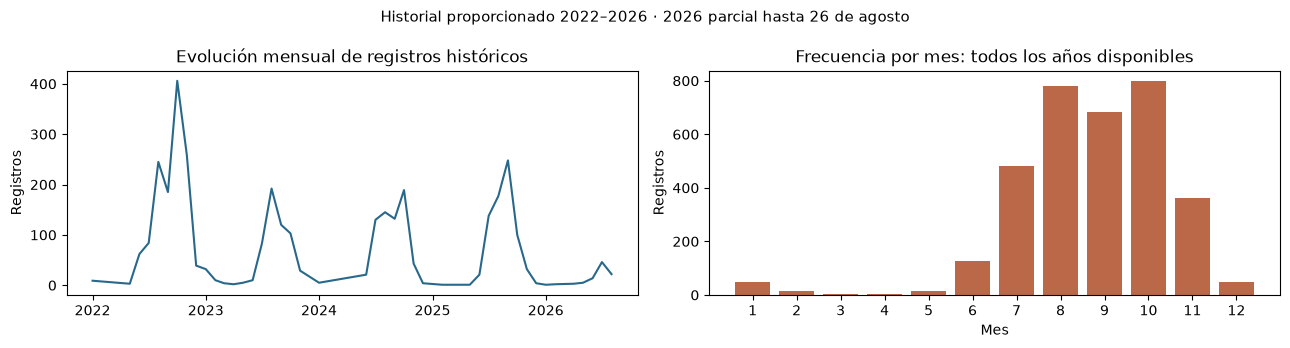

,COB_AFECTA_VALOR
count,3365.000000
mean,6.381195
std,79.173016
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,3000.000000


Rango: 2022-01-01 a 2026-08-26


In [2]:
history=inputs.history.copy()
provincias=provinces_from_history(history)
print('Provincias disponibles:',len(provincias),'—',', '.join(provincias))
display(history.groupby('ANIO').size().rename('REGISTROS').to_frame())
display(history.groupby('PROVINCIA').size().sort_values(ascending=False).rename('REGISTROS').to_frame())
dates=pd.to_datetime(history.FECHA_INICIO,errors='coerce')
monthly=dates.dt.to_period('M').value_counts().sort_index()
season=dates.dt.month.value_counts().reindex(range(1,13),fill_value=0).sort_index()
fig,axes=plt.subplots(1,2,figsize=(13,3.5))
axes[0].plot(monthly.index.to_timestamp(),monthly.values,color='#28698b')
axes[0].set_title('Evolución mensual de registros históricos')
axes[0].set_ylabel('Registros')
axes[1].bar(season.index,season.values,color='#bb6849')
axes[1].set_xticks(range(1,13));axes[1].set_title('Frecuencia por mes: todos los años disponibles')
axes[1].set_xlabel('Mes');axes[1].set_ylabel('Registros')
fig.suptitle('Historial proporcionado 2022–2026 · 2026 parcial hasta 26 de agosto',fontsize=11)
fig.tight_layout()
fig.savefig(ROOT/'outputs/figures/04_contexto_mensual.png',dpi=150)
plt.show()
display(history[['COB_AFECTA_VALOR']].describe())
print('Rango:',history.FECHA_INICIO.min(),'a',history.FECHA_INICIO.max())

## 2. Selección y perfiles editables

La siguiente celda define una demostración con cuatro provincias y perfiles distintos. Se puede elegir cualquier subconjunto de `provincias`, incluido `[]` o las 13. La CLI permite la misma selección sin editar Python. Cada ejecución crea tablas nuevas; cambiar selección, perfiles, pesos o archivos de entrada cambia el identificador SHA-256 del escenario. Un plan anterior no pasa la validación de un escenario nuevo.

`BOMBEROS` y `PERSONAL_APOYO` generan personal total; más de diez bomberos se deriva del recuento. Desactivar fauna elimina demanda veterinaria automática. `HERRAMIENTAS_NECESARIAS=False` elimina herramientas automáticas. Las cantidades manuales adicionales se suman por recurso, incluso si no existe demanda automática. Los pesos y coeficientes son supuestos editables en `config/phase4.json`.

In [3]:
SELECCIONADAS=['ANTA','CALCA','URUBAMBA','PARURO']
PERFILES=json.loads((ROOT/'config/ejemplo_perfiles_fase4.json').read_text())
# Para otra selección: cambie SELECCIONADAS y, si desea, este diccionario.
# Solo se pasan perfiles de provincias activas; las otras usan valores predeterminados.
PERFILES={p:PERFILES[p] for p in SELECCIONADAS if p in PERFILES}
RECEPTORES={}  # Opcional: {'PARURO':'RE04'} conserva Accha como receptor alternativo.
PESOS={'magnitud':.35,'personal':.25,'fauna':.25,'urgencia':.15}
scenario=create_scenario(inputs,SELECCIONADAS,PERFILES,RECEPTORES,PESOS)
print('Escenario:',scenario.scenario_id)
display(scenario.coverage)
display(scenario.profiles)
if not SELECCIONADAS: print('Escenario vacío: seleccione al menos una provincia para obtener entregas.')

Escenario: e183b86581fe680be96868c0efe425f5cc447334b2b886456effa1fa14696cbc


,PROVINCIA,PUNTO_ID,PREPARADO,ESTADO,NOMBRE,FUENTE_COORDENADA
0,ANTA,CAP_0803,True,PREPARADO_DEMO,Anta: referencia de localidad OSM (no almacén ...,https://www.openstreetmap.org/node/2367668493
1,CALCA,CAP_0804,True,PREPARADO_DEMO,Calca: referencia de localidad OSM (no almacén...,https://www.openstreetmap.org/node/436613486
2,PARURO,CAP_0810,True,PREPARADO_DEMO,Paruro: referencia de localidad OSM (no almacé...,https://www.openstreetmap.org/node/2314231210
3,URUBAMBA,CAP_0813,True,PREPARADO_DEMO,Urubamba: referencia de localidad OSM (no alma...,https://www.openstreetmap.org/node/441008049


,PROVINCIA,PUNTO_ID,INCENDIO_ID,BOMBEROS,PERSONAL_APOYO,MAS_DE_DIEZ_BOMBEROS,PERSONAL_DESPLEGADO,...,FACTOR_HUMO,URGENCIA_RELATIVA,HERRAMIENTAS_NECESARIAS,PLAZO_HORAS,CENTRO_PREFERENTE_ID,ORIGEN,PRIORIDAD_BASE
0,ANTA,CAP_0803,SIM-ANTA,80,10,True,90,...,1.0,1.0,True,4.0,COER_CUSCO,SIMULADO_NO_INCENDIO_ACTUAL,75.8333
1,CALCA,CAP_0804,SIM-CALCA,50,10,True,60,...,1.0,0.8,True,5.0,COER_CUSCO,SIMULADO_NO_INCENDIO_ACTUAL,66.6667
2,PARURO,CAP_0810,SIM-PARURO,45,10,True,55,...,1.2,0.9,True,6.0,COER_CUSCO,SIMULADO_NO_INCENDIO_ACTUAL,68.1944
3,URUBAMBA,CAP_0813,SIM-URUBAMBA,25,15,True,40,...,1.0,1.0,True,4.0,COER_CUSCO,SIMULADO_NO_INCENDIO_ACTUAL,66.8611


## 3. Receptores y cobertura real

El registro de receptores diferencia provincia y localidad exacta. Las coordenadas de las capitales se verifican contra nodos `place` del PBF OSM y conservan URL, ID y etiquetas de procedencia. Los receptores demo anteriores se mantienen como alternativas. La selección provincial procede del historial, nunca de la matriz.

La red de fase 04 se guarda aparte de las fases 02/03. Las matrices dirigidas conservan sentidos viales; km y minutos corresponden al mismo camino de menor tiempo estimado. Un receptor sin asociación vial válida o sin ida y retorno queda señalado y conserva su demanda pendiente. No se sustituye por distancia en línea recta. Ver `docs/receptores_fase4.md` y `data/geo/phase4/snap_report.csv`.

Para actualizar puntos, editar el registro y ejecutar `scripts/prepare_phase4_network.py`; si falta cobertura, regenerar antes el extracto siguiendo `docs/phase4.md`. El acceso desde el nodo de carretera al punto receptor sigue sin validación operativa.

In [4]:
display(inputs.receivers[['PROVINCIA','PUNTO_ID','NOMBRE','PREDETERMINADO','FUENTE_COORDENADA']])
snap=pd.read_csv(ROOT/'data/geo/phase4/snap_report.csv',encoding='utf-8-sig')
display(snap[['PUNTO_ID','DISTANCIA_A_NODO_M','SNAP_OK']].round(2))
active=['COER_CUSCO',*scenario.profiles.PUNTO_ID.tolist()]
active=[p for p in active if p in inputs.durations.index]
display(inputs.durations.loc[active,active].round(1))

,PROVINCIA,PUNTO_ID,NOMBRE,PREDETERMINADO,FUENTE_COORDENADA
0,ACOMAYO,CAP_0802,Acomayo: referencia de localidad OSM (no almac...,True,https://www.openstreetmap.org/node/2317137705
1,ANTA,CAP_0803,Anta: referencia de localidad OSM (no almacén ...,True,https://www.openstreetmap.org/node/2367668493
2,ANTA,RE01,Receptor demo Anta,False,PUNTO_DEMO_NO_PUNTO_SEGURO_VERIFICADO
3,CALCA,CAP_0804,Calca: referencia de localidad OSM (no almacén...,True,https://www.openstreetmap.org/node/436613486
4,CALCA,RE03,Receptor demo Calca,False,PUNTO_DEMO_NO_PUNTO_SEGURO_VERIFICADO
5,CANAS,CAP_0805,Yanaoca: referencia de localidad OSM (no almac...,True,https://www.openstreetmap.org/node/441888431
6,CANCHIS,CAP_0806,Sicuani: referencia de localidad OSM (no almac...,True,https://www.openstreetmap.org/node/262945603
7,CHUMBIVILCAS,CAP_0807,Santo Tomás: referencia de localidad OSM (no a...,True,https://www.openstreetmap.org/node/467653110
8,CUSCO,CAP_0801,"Cusco (OSM: Cuzco): referencia de localidad, n...",True,https://www.openstreetmap.org/node/59115290
9,ESPINAR,CAP_0808,Yauri: referencia de localidad OSM (no almacén...,True,https://www.openstreetmap.org/node/267367682


,PUNTO_ID,DISTANCIA_A_NODO_M,SNAP_OK
0,COER_CUSCO,33.95,True
1,CAP_0802,20.14,True
2,CAP_0803,47.90,True
3,RE01,44.36,True
4,CAP_0804,74.73,True
5,RE03,49.44,True
6,CAP_0805,43.39,True
7,CAP_0806,36.26,True
8,CAP_0807,16.37,True
9,CAP_0801,48.46,True


,COER_CUSCO,CAP_0803,CAP_0804,CAP_0810,CAP_0813
PUNTO_ID,,,,,
COER_CUSCO,0.0,28.3,56.9,72.7,59.4
CAP_0803,28.4,0.0,57.5,97.4,38.5
CAP_0804,56.5,57.3,0.0,127.2,22.5
CAP_0810,72.6,97.4,126.7,0.0,128.5
CAP_0813,59.7,38.7,22.9,128.7,0.0


## 4. Demanda, prioridad e inventario

Se reutiliza `logistics.demand_quantities`: agua = `ceil(personal × 4)` botellas; mascarillas = `ceil(personal × 1,2 × humo)`; palas y hachas según trabajo manual; paquetes veterinarios según fauna y botiquines según personal. Todos son coeficientes de simulación para este horizonte, sin prescripción de consumo o atención.

La prioridad $P_i=100\sum_f w_f a_{if}/\max_j a_{jf}$ usa los pesos 35/25/25/15; una columna cuyo máximo es cero aporta cero. Cada recurso ajusta esa puntuación con su factor. No se utiliza el área histórica sin unidad verificada.

El stock de fase 03 **permanece fijo al cambiar la selección**. Se gasta únicamente inventario libre en COER, recibido y liberado al comienzo, con lotes vigentes hasta el final del horizonte. Esta regla conservadora excluye vencimientos intermedios, promesas, cuarentena, recepción futura y stock localizado en Paruro. Se documenta el stock no utilizado en hubs; no se simulan transferencias implícitas.

In [5]:
demand=scenario.requests.pivot(index='PROVINCIA',columns='RECURSO_ID',values='CANTIDAD_SOLICITADA') if len(scenario.requests) else pd.DataFrame()
display(demand)
display(scenario.profiles[['PROVINCIA','PRIORIDAD_BASE','BOMBEROS','MAS_DE_DIEZ_BOMBEROS','FAUNA_REQUIERE_ATENCION']])
display(pd.Series(usable_stock(inputs,scenario.config),name='STOCK_COER_UTILIZABLE').to_frame())
display(inputs.inventory.loc[inputs.inventory.CENTRO_ID.ne('COER_CUSCO')])

RECURSO_ID,AGUA,BOTIQUIN_BRIGADA,HACHA,MASCARILLA,PALA,PAQUETE_VETERINARIO
PROVINCIA,,,,,,
ANTA,360,4,9,108,24,1
CALCA,240,3,5,72,12,3
PARURO,220,3,4,80,10,5
URUBAMBA,160,2,2,48,5,8


,PROVINCIA,PRIORIDAD_BASE,BOMBEROS,MAS_DE_DIEZ_BOMBEROS,FAUNA_REQUIERE_ATENCION
0,ANTA,75.8333,80,True,1
1,CALCA,66.6667,50,True,12
2,PARURO,68.1944,45,True,20
3,URUBAMBA,66.8611,25,True,30


,STOCK_COER_UTILIZABLE
AGUA,670
MASCARILLA,258
PALA,27
HACHA,12
PAQUETE_VETERINARIO,8
BOTIQUIN_BRIGADA,8


,CENTRO_ID,RECURSO_ID,CANTIDAD_DISPONIBLE,CANTIDAD_RESERVADA,ORIGEN
6,HUB_PARURO,AGUA,112,0,SIMULADO
7,HUB_PARURO,MASCARILLA,39,0,SIMULADO
8,HUB_PARURO,PALA,6,0,SIMULADO
9,HUB_PARURO,HACHA,3,0,SIMULADO
10,HUB_PARURO,PAQUETE_VETERINARIO,3,0,SIMULADO
11,HUB_PARURO,BOTIQUIN_BRIGADA,2,0,SIMULADO


## 5. Modelo matemático clásico

Se enumeran tours $k\in K_v$ de uno a tres destinos seleccionados, con origen y retorno COER. Para cada vehículo se eliminan tours sin conexión, con descarga finalizada después del plazo del receptor o con retorno posterior a su disponibilidad/horizonte. Esta enumeración incluye ambos sentidos y órdenes diferentes. Cada vehículo realiza **un viaje** y puede entregar parcialmente varias solicitudes.

Variables: $y_{vk}\in\{0,1\}$ selecciona un tour y $q_{vir}\in\mathbb Z_{\ge0}$ asigna unidades del recurso $r$ al receptor $i$ en el vehículo $v$. Sea $d_{ir}$ la demanda, $S_r$ el stock utilizable, $p_{ir}$ la prioridad por recurso y $A_{ik}=1$ cuando el tour visita $i$.

$$\min \sum_{v,k}(c_d D_k+c_t T_k)y_{vk}+\lambda\sum_{i,r:d_{ir}>0}\frac{p_{ir}}{100}\left(1-\frac{\sum_v q_{vir}}{d_{ir}}\right).$$

Se penaliza la **fracción faltante de cada pedido**, sin sumar botellas y herramientas como una unidad homogénea. Distancia y tiempo tienen coeficientes explícitos, y la prioridad afecta las cantidades elegidas.

$$\sum_k y_{vk}\le1,\quad \sum_v q_{vir}\le d_{ir},\quad \sum_{v,i}q_{vir}\le S_r,$$
$$\sum_{i,r}m_rq_{vir}\le C_v^{kg},\quad\sum_{i,r}u_rq_{vir}\le C_v^{m^3},$$
$$q_{vir}\le d_{ir}\sum_k A_{ik}y_{vk},\qquad \sum_rq_{vir}\ge\sum_k A_{ik}y_{vk}.$$

La última desigualdad exige entregar al menos una unidad en cada parada. Los recursos que requieren autorización simulada se fijan a cero si falta. Como solo hay descargas, el máximo de peso y volumen ocurre al salir del COER; la carga restante se concilia en cada parada.

Se resuelve con `scipy.optimize.milp` y HiGHS. `OPTIMO_DEL_MODELO_RESTRINGIDO` prueba el óptimo **del modelo con hasta tres paradas por viaje**, no del VRP general. Si se alcanza el límite del solver se publica el estado factible y la brecha, sin afirmar optimalidad. No se usan números aleatorios; se registra configuración, semilla declarada y hashes.

In [6]:
plan=solve_classical(scenario)
print('Estado:',plan.metrics['estado_solver'])
print('Tours factibles enumerados:',plan.metrics['tours_candidatos'])
print('Vehículos:',plan.metrics['vehiculos_utilizados'])
print('Distancia vial total: %.2f km | Tiempo de conducción: %.1f min' % (plan.metrics['distancia_km'],plan.metrics['duracion_vial_min']))
print('Objetivo con plan: %.3f | Sin entregas: %.3f' % (plan.metrics['objetivo'],plan.metrics['objetivo_sin_entregas']))
display(pd.DataFrame(plan.routes))
display(plan.stops)
display(plan.assignments)
display(plan.unmet[['PROVINCIA','RECURSO_ID','CANTIDAD_PENDIENTE','CANTIDAD_ASIGNADA','CANTIDAD_FALTANTE','COBERTURA','MOTIVO']])

Estado: OPTIMO_DEL_MODELO_RESTRINGIDO
Tours factibles enumerados: 93
Vehículos: 2
Distancia vial total: 248.76 km | Tiempo de conducción: 291.4 min
Objetivo con plan: 3821.503 | Sin entregas: 14432.887


,VEHICULO_ID,SECUENCIA,SALIDA_EN,RETORNO_EN,DISTANCIA_KM,DURACION_VIAL_MIN,CARGA_INICIAL_KG,VOLUMEN_INICIAL_M3,CAPACIDAD_KG,CAPACIDAD_M3
0,VEH-01,"[COER_CUSCO, CAP_0810, COER_CUSCO]",2026-10-24T08:00:00-05:00,2026-10-24T10:40:14.314667431-05:00,117.595986,145.238578,189.40,0.4260,650.0,3.0
1,VEH-03,"[COER_CUSCO, CAP_0803, CAP_0813, CAP_0804, COE...",2026-10-24T08:00:00-05:00,2026-10-24T11:11:10.698617456-05:00,131.162409,146.178310,365.57,0.7607,1200.0,6.0


,VEHICULO_ID,ORDEN,PUNTO_ID,PROVINCIA,LLEGADA_EN,ENTREGA_EN,CARGA_ANTES_KG,CARGA_DESPUES_KG,VOLUMEN_ANTES_M3,VOLUMEN_DESPUES_M3
0,VEH-01,1,CAP_0810,PARURO,2026-10-24T09:12:39.969429377-05:00,2026-10-24T09:27:39.969429377-05:00,189.40,0.000000e+00,0.4260,0.0000
1,VEH-03,1,CAP_0803,ANTA,2026-10-24T08:28:20.450866843-05:00,2026-10-24T08:43:20.450866843-05:00,365.57,3.274000e+02,0.7607,0.6900
2,VEH-03,2,CAP_0813,URUBAMBA,2026-10-24T09:21:48.735586055-05:00,2026-10-24T09:36:48.735586055-05:00,327.40,2.050800e+02,0.6900,0.4588
3,VEH-03,3,CAP_0804,CALCA,2026-10-24T09:59:41.657451437-05:00,2026-10-24T10:14:41.657451437-05:00,205.08,2.842171e-14,0.4588,0.0000


,SOLICITUD_ID,PROVINCIA,PUNTO_ID,RECURSO_ID,VEHICULO_ID,CANTIDAD_ASIGNADA,UNIDAD,PESO_KG,VOLUMEN_M3,ENTREGA_EN,ESCENARIO_ID
0,SOL-CAP_0810-AGUA,PARURO,CAP_0810,AGUA,VEH-01,220,BOTELLA,143.00,0.1760,2026-10-24T09:27:39.969429377-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
1,SOL-CAP_0810-MASCARILLA,PARURO,CAP_0810,MASCARILLA,VEH-01,80,UNIDAD,1.20,0.0120,2026-10-24T09:27:39.969429377-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
2,SOL-CAP_0810-PALA,PARURO,CAP_0810,PALA,VEH-01,10,UNIDAD,20.00,0.1200,2026-10-24T09:27:39.969429377-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
3,SOL-CAP_0810-HACHA,PARURO,CAP_0810,HACHA,VEH-01,4,UNIDAD,7.20,0.0320,2026-10-24T09:27:39.969429377-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
4,SOL-CAP_0810-PAQUETE_VETERINARIO,PARURO,CAP_0810,PAQUETE_VETERINARIO,VEH-01,4,PAQUETE,12.00,0.0560,2026-10-24T09:27:39.969429377-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
5,SOL-CAP_0810-BOTIQUIN_BRIGADA,PARURO,CAP_0810,BOTIQUIN_BRIGADA,VEH-01,3,KIT,6.00,0.0300,2026-10-24T09:27:39.969429377-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
6,SOL-CAP_0803-AGUA,ANTA,CAP_0803,AGUA,VEH-03,50,BOTELLA,32.50,0.0400,2026-10-24T08:43:20.450866843-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
7,SOL-CAP_0803-MASCARILLA,ANTA,CAP_0803,MASCARILLA,VEH-03,58,UNIDAD,0.87,0.0087,2026-10-24T08:43:20.450866843-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
8,SOL-CAP_0803-HACHA,ANTA,CAP_0803,HACHA,VEH-03,1,UNIDAD,1.80,0.0080,2026-10-24T08:43:20.450866843-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...
9,SOL-CAP_0803-PAQUETE_VETERINARIO,ANTA,CAP_0803,PAQUETE_VETERINARIO,VEH-03,1,PAQUETE,3.00,0.0140,2026-10-24T08:43:20.450866843-05:00,e183b86581fe680be96868c0efe425f5cc447334b2b886...


,PROVINCIA,RECURSO_ID,CANTIDAD_PENDIENTE,CANTIDAD_ASIGNADA,CANTIDAD_FALTANTE,COBERTURA,MOTIVO
0,ANTA,AGUA,360,50,310,0.138889,STOCK_CAPACIDAD_COSTO_O_LIMITE_DE_PARADAS
1,ANTA,MASCARILLA,108,58,50,0.537037,STOCK_CAPACIDAD_COSTO_O_LIMITE_DE_PARADAS
2,ANTA,PALA,24,0,24,0.000000,STOCK_CAPACIDAD_COSTO_O_LIMITE_DE_PARADAS
3,ANTA,HACHA,9,1,8,0.111111,STOCK_CAPACIDAD_COSTO_O_LIMITE_DE_PARADAS
4,ANTA,PAQUETE_VETERINARIO,1,1,0,1.000000,CUBIERTA
5,ANTA,BOTIQUIN_BRIGADA,4,0,4,0.000000,STOCK_CAPACIDAD_COSTO_O_LIMITE_DE_PARADAS
6,CALCA,AGUA,240,240,0,1.000000,CUBIERTA
7,CALCA,MASCARILLA,72,72,0,1.000000,CUBIERTA
8,CALCA,PALA,12,12,0,1.000000,CUBIERTA
9,CALCA,HACHA,5,5,0,1.000000,CUBIERTA


## 6. Cobertura por recurso y geometrías de las rutas

Cada porcentaje usa su propia unidad. El mapa muestra solo los destinos seleccionados, COER y las carreteras de los tours elegidos. Pasar por otra provincia no crea solicitudes ni paradas allí. No se asigna stock de hubs ni se dibujan centros como si se hubieran visitado.

,solicitado,asignado,faltante,stock_coer_utilizable,saldo_coer,cobertura
AGUA,980.0,670.0,310.0,670.0,0.0,0.683673
BOTIQUIN_BRIGADA,12.0,8.0,4.0,8.0,0.0,0.666667
HACHA,20.0,12.0,8.0,12.0,0.0,0.600000
MASCARILLA,308.0,258.0,50.0,258.0,0.0,0.837662
PALA,51.0,27.0,24.0,27.0,0.0,0.529412
PAQUETE_VETERINARIO,17.0,8.0,9.0,8.0,0.0,0.470588


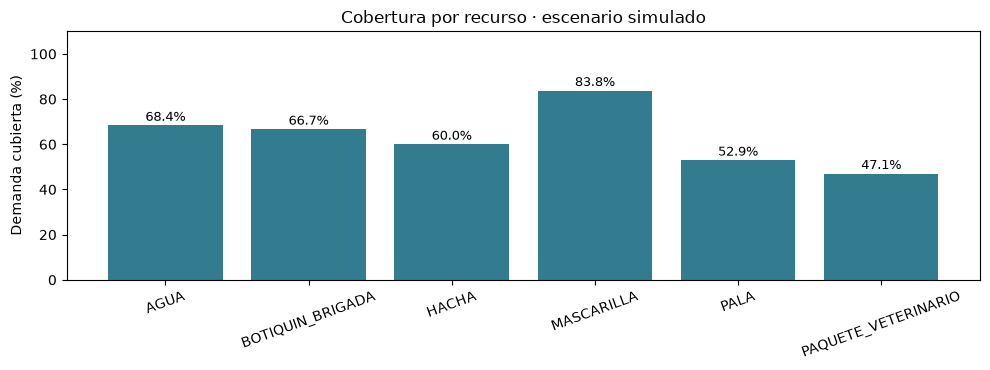

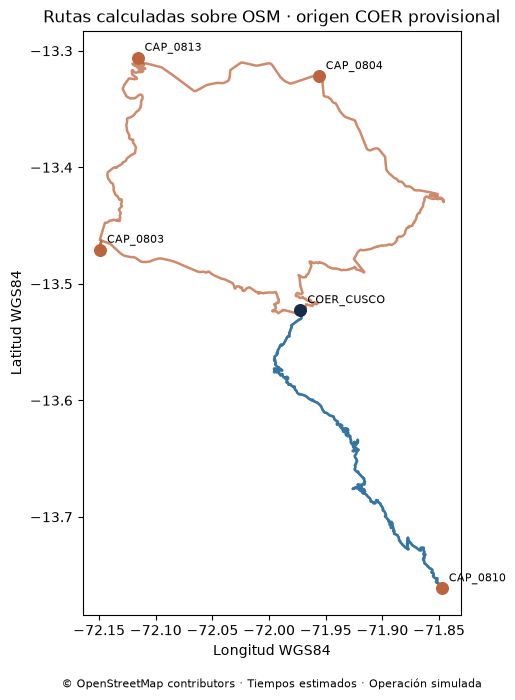

In [7]:
resource_results=pd.DataFrame(plan.metrics['recursos']).T
if len(resource_results):
    display(resource_results)
    fig,ax=plt.subplots(figsize=(10,3.8))
    ax.bar(resource_results.index,resource_results.cobertura.astype(float)*100,color='#337b8f')
    ax.set_ylim(0,110);ax.set_ylabel('Demanda cubierta (%)');ax.set_title('Cobertura por recurso · escenario simulado')
    ax.tick_params(axis='x',labelrotation=20)
    for i,v in enumerate(resource_results.cobertura.astype(float)*100): ax.text(i,v+2,f'{v:.1f}%',ha='center',fontsize=9)
    fig.tight_layout();fig.savefig(ROOT/'outputs/figures/04_cobertura_clasica.png',dpi=150);plt.show()

fig,ax=plt.subplots(figsize=(8,7))
colors=['#286c9b','#bd643b','#54885d']
vehicles=[r['VEHICULO_ID'] for r in plan.routes]
for feature in plan.geojson['features']:
    p=feature['properties'];xy=np.array(feature['geometry']['coordinates'])
    ax.plot(xy[:,0],xy[:,1],color=colors[vehicles.index(p['VEHICULO_ID'])%len(colors)],lw=1.8,alpha=.75)
points=pd.read_csv(ROOT/'config/puntos_logisticos_fase4.csv',encoding='utf-8-sig')
points=points.loc[points.PUNTO_ID.isin(['COER_CUSCO',*scenario.profiles.PUNTO_ID.tolist()])]
for p in points.itertuples():
    ax.scatter(p.LONGITUD,p.LATITUD,s=70,color='#172d47' if p.PUNTO_ID=='COER_CUSCO' else '#bb643d',zorder=5)
    ax.annotate(p.PUNTO_ID,(p.LONGITUD,p.LATITUD),xytext=(5,5),textcoords='offset points',fontsize=8)
ax.set_aspect(1/np.cos(np.deg2rad(points.LATITUD.mean())));ax.set_xlabel('Longitud WGS84');ax.set_ylabel('Latitud WGS84')
ax.set_title('Rutas calculadas sobre OSM · origen COER provisional')
fig.text(.5,.01,'© OpenStreetMap contributors · Tiempos estimados · Operación simulada',ha='center',fontsize=8)
fig.tight_layout(rect=[0,.03,1,1]);fig.savefig(ROOT/'outputs/figures/04_rutas_clasicas.png',dpi=150);plt.show()

In [8]:
import folium
map_object=folium.Map(location=[-13.52,-71.97],tiles='OpenStreetMap',zoom_start=9)
for feature in plan.geojson['features']:
    folium.GeoJson(feature,tooltip=f"{feature['properties']['VEHICULO_ID']}: {feature['properties']['ORIGEN']} → {feature['properties']['DESTINO']}",style_function=lambda f:{'color':colors[vehicles.index(f['properties']['VEHICULO_ID'])%len(colors)],'weight':4}).add_to(map_object)
for p in points.itertuples():
    folium.Marker([p.LATITUD,p.LONGITUD],tooltip=p.NOMBRE,icon=folium.Icon(color='blue' if p.PUNTO_ID=='COER_CUSCO' else 'orange')).add_to(map_object)
map_object.get_root().html.add_child(folium.Element('<div style="position:fixed;bottom:20px;left:20px;z-index:9999;background:white;padding:12px;max-width:350px">QFire Cusco · Plan clásico simulado<br>COER provisional y receptores sin validación operativa.<br>No es una herramienta oficial de emergencia.</div>'))
map_name='04_plan_clasico_'+scenario.scenario_id[:12]+'.html'
map_object.save(ROOT/'outputs/maps'/map_name)
display(IFrame(src='../outputs/maps/'+map_name,width='100%',height=550))

## 7. Pruebas y escenarios de aceptación

Se prueba selección vacía, una provincia, Canas/Espinar, Calca/Anta/Chumbivilcas y las 13; se concilian inventario, capacidades, plazos y origen. La batería completa añade 8.192 combinaciones al contrato del selector, fauna, cambio de perfiles, prioridad bajo escasez, vencimientos, recursos reservados y rechazo de planes obsoletos.

Que se puedan seleccionar 13 provincias no garantiza atender todas con tres vehículos, una salida por vehículo, ventanas y stock escaso. Los faltantes conservan demanda y motivo. Los casos siguientes se calculan nuevamente con el mismo inventario fijo.

In [9]:
assert validate_plan(scenario,plan)
acceptance=[]
for selected in [[],['URUBAMBA'],['CANAS','ESPINAR'],['CALCA','ANTA','CHUMBIVILCAS'],provincias]:
    case=create_scenario(inputs,selected)
    result=solve_classical(case)
    assert validate_plan(case,result)
    assert set(case.requests.PROVINCIA)==set(selected)
    assert set(result.assignments.PROVINCIA)<=set(selected)
    assert all(r['SECUENCIA'][0]==r['SECUENCIA'][-1]=='COER_CUSCO' for r in result.routes)
    if not selected: assert not result.routes and result.assignments.empty and case.requests.empty
    acceptance.append({'seleccion':', '.join(selected) or '(vacía)','provincias_con_pedido':case.requests.PROVINCIA.nunique(),
        'provincias_atendidas':len(result.metrics['provincias_atendidas']),'vehiculos':len(result.routes),'estado':result.metrics['estado_solver'],
        'limitaciones_viales':', '.join(result.metrics['provincias_sin_cobertura_vial']),'validacion':'APROBADA'})
display(pd.DataFrame(acceptance))
other_selection=[] if scenario.selected else ['CALCA']
other=create_scenario(inputs,other_selection)
assert other.scenario_id!=scenario.scenario_id
try:
    validate_plan(other,plan)
    raise AssertionError('Se aceptó un plan obsoleto')
except ValueError as error: print('Control esperado:',error)

,seleccion,provincias_con_pedido,provincias_atendidas,vehiculos,estado,limitaciones_viales,validacion
0,(vacía),0,0,0,ESCENARIO_VACIO,,APROBADA
1,URUBAMBA,1,1,1,OPTIMO_DEL_MODELO_RESTRINGIDO,,APROBADA
2,"CANAS, ESPINAR",2,2,1,OPTIMO_DEL_MODELO_RESTRINGIDO,,APROBADA
3,"CALCA, ANTA, CHUMBIVILCAS",3,3,1,OPTIMO_DEL_MODELO_RESTRINGIDO,,APROBADA
4,"ACOMAYO, ANTA, CALCA, CANAS, CANCHIS, CHUMBIVI...",13,9,3,OPTIMO_DEL_MODELO_RESTRINGIDO,,APROBADA


Control esperado: Resultado obsoleto: escenario diferente.


## 8. Exportación y cierre

Cada escenario se guarda en su carpeta SHA-256 con solicitudes, perfiles, cobertura, asignaciones, faltantes, paradas, métricas, configuración y geometrías GeoJSON. `latest.json` apunta a la última exportación, incluso si está vacía. Estos contratos pueden alimentar una aplicación posterior.

**Simplificaciones:** depósito único, sin recogidas ni transferencias, un viaje por vehículo y máximo tres paradas por viaje. No se modelan tráfico, bloqueos, restricciones de giro por relaciones OSM o aptitud de cada vehículo. El reloj es ficticio. El stock de Paruro permanece sin gastar. El resultado es un plan computado de una simulación; no representa despachos realizados.

La comparación cuántica, notebook 05, aplicación web y replanificación quedan para fases posteriores.

In [10]:
folder=export_plan(scenario,plan)
print('Resultados:',folder.relative_to(ROOT))
print('Puntero vigente:',(folder.parent/'latest.json').relative_to(ROOT))
display(pd.DataFrame({'ARCHIVO':[p.name for p in sorted(folder.iterdir())],'BYTES':[p.stat().st_size for p in sorted(folder.iterdir())]}))
print('Pruebas completas: python -m unittest discover -s tests -v')
print('Validación del plan:',validate_plan(scenario,plan))

Resultados: data/results/phase4/e183b86581fe680be96868c0efe425f5cc447334b2b886456effa1fa14696cbc
Puntero vigente: data/results/phase4/latest.json


,ARCHIVO,BYTES
0,asignaciones.csv,3904
1,cobertura.csv,624
2,configuracion.json,2308
3,faltantes.csv,7829
4,metricas.json,4096
5,paradas.csv,728
6,perfiles.csv,776
7,rutas.geojson,570418
8,rutas.json,940
9,solicitudes.csv,7075


Pruebas completas: python -m unittest discover -s tests -v
Validación del plan: True
